In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\emp_promotion_prediction.csv")

In [3]:
df.head()

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
0,E001,Graduate,2,Average,30000,HR,No
1,E002,Postgraduate,5,Good,60000,IT,Yes
2,E003,Graduate,3,Good,45000,Sales,Yes
3,E004,Graduate,1,Poor,25000,HR,No
4,E005,Postgraduate,6,Excellent,75000,IT,Yes


In [4]:
df.tail()

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
195,E196,Graduate,6,Good,69000,Operations,Yes
196,E197,Postgraduate,7,Excellent,91000,Finance,Yes
197,E198,Graduate,4,Average,40000,HR,No
198,E199,Diploma,6,Good,46000,Support,Yes
199,E200,Graduate,2,Poor,26000,Support,No


In [5]:
df.shape

(200, 7)

In [6]:
df.head()

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
0,E001,Graduate,2,Average,30000,HR,No
1,E002,Postgraduate,5,Good,60000,IT,Yes
2,E003,Graduate,3,Good,45000,Sales,Yes
3,E004,Graduate,1,Poor,25000,HR,No
4,E005,Postgraduate,6,Excellent,75000,IT,Yes


In [7]:
df.sample()

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
66,E067,Graduate,4,Average,42000,HR,No


In [9]:
df["Performance"]

0        Average
1           Good
2           Good
3           Poor
4      Excellent
         ...    
195         Good
196    Excellent
197      Average
198         Good
199         Poor
Name: Performance, Length: 200, dtype: object

In [10]:
df

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
0,E001,Graduate,2,Average,30000,HR,No
1,E002,Postgraduate,5,Good,60000,IT,Yes
2,E003,Graduate,3,Good,45000,Sales,Yes
3,E004,Graduate,1,Poor,25000,HR,No
4,E005,Postgraduate,6,Excellent,75000,IT,Yes
...,...,...,...,...,...,...,...
195,E196,Graduate,6,Good,69000,Operations,Yes
196,E197,Postgraduate,7,Excellent,91000,Finance,Yes
197,E198,Graduate,4,Average,40000,HR,No
198,E199,Diploma,6,Good,46000,Support,Yes


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.isna().sum()

EmpID              0
Education          0
ExperienceYears    0
Performance        0
Salary             0
Department         0
Promoted           0
dtype: int64

In [13]:
df.drop(columns="EmpID",inplace=True)

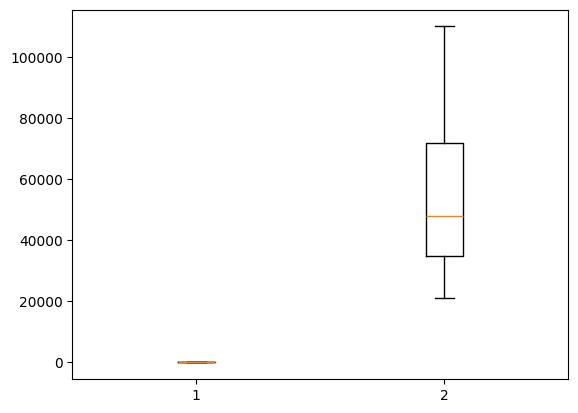

In [16]:
import matplotlib.pyplot as plt


plt.boxplot(df[["ExperienceYears","Salary"]])
plt.show()

In [19]:
df["Education"].value_counts()

Education
Graduate        100
Postgraduate     51
Diploma          49
Name: count, dtype: int64

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score as a

In [23]:
le = LabelEncoder()

In [27]:
df["Education"] = le.fit_transform(df["Education"])
df["Performance"] = le.fit_transform(df["Performance"])
df["Department"] = le.fit_transform(df["Department"])
df["Promoted"] = le.fit_transform(df["Promoted"])

In [35]:
from sklearn.model_selection import train_test_split

x = df[["Education","ExperienceYears","Performance","Salary","Department"]]
y = df["Promoted"]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=222)

In [36]:
model = DecisionTreeClassifier()

In [37]:
model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [38]:
y_predict = model.predict(x_test)

In [46]:
y_predict.size

40

In [45]:
y_test.size

40

In [41]:
acc = accuracy_score(y_test,y_predict)

In [44]:
acc

1.0

In [48]:
print("Training Accuracy:", model.score(x_train, y_train))
print("Testing Accuracy:", model.score(x_test, y_test))

Training Accuracy: 1.0
Testing Accuracy: 1.0


In [49]:
df

,Education,ExperienceYears,Performance,Salary,Department,Promoted
0,1,2,0,30000,1,0
1,2,5,2,60000,2,1
2,1,3,2,45000,4,1
3,1,1,3,25000,1,0
4,2,6,1,75000,2,1
...,...,...,...,...,...,...
195,1,6,2,69000,3,1
196,2,7,1,91000,0,1
197,1,4,0,40000,1,0
198,0,6,2,46000,5,1


In [50]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\emp_promotion_prediction.csv")

In [51]:
df.head()

,EmpID,Education,ExperienceYears,Performance,Salary,Department,Promoted
0,E001,Graduate,2,Average,30000,HR,No
1,E002,Postgraduate,5,Good,60000,IT,Yes
2,E003,Graduate,3,Good,45000,Sales,Yes
3,E004,Graduate,1,Poor,25000,HR,No
4,E005,Postgraduate,6,Excellent,75000,IT,Yes


In [55]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import  accuracy_score


In [56]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\crop_yield_dataset.csv")

In [57]:
df.head()

,rainfall_mm,temperature_celsius,fertilizer_kg_per_ha,yield_tons_per_ha
0,1322.6,29.4,117.0,5.65
1,783.5,20.5,140.4,4.37
2,908.2,30.7,88.1,2.61
3,1001.9,25.4,140.8,4.81
4,702.8,28.8,107.8,3.47


In [ ]:
x = df[[